-   1.开场三问
    -   1.1 11/19 双轴表诊断出什么？
        -   双轴表诊断出了DL重建在去伪影和保真组织两个维度上的表现，抗伪影部分，消声区的CNR从重建前的52.86提升到了25379，说明伪影完全清除；消声区的标准差从重建前的0.0162降成了0，说明背景完全干净。保组织部分，z=12mm z=25mm点目标恢复率分别为1.000和1.032，说明保住了该亮点，但z深度=34mm时，点目标恢复率为0.898，丢了百分之十，需证明因果链深度 ↑ → 超声衰减 ↑ → 信号变弱 → 点在低质图里本来就暗 → DL 在"去伪影"时更容易把这个弱信号当成伪影一起抹掉 → 恢复率下降。
    -   1.2 今天在整条链的哪一环？
        -   1.2.1换网络结构：普通 UNet → 残差 UNet（输出学增量 Δ，重建 = 低质 + Δ）；
        -   1.2.2换损失函数：普通 L1 → 点目标/边缘加权 L1（让 loss 盯住稀疏强点）
    -   1.3 今天做完，我能多做哪一件具体的事？
        -   今天用"残差学习 + 点目标/边缘加权"两个手段去修复，若修复版的点目标恢复率（尤其 z=34mm）回升，则 H2 假设得到正面验证。
    -   今日核心：今天的"修复"是两把钥匙：残差结构 + 加权损失，且要做消融看各自作用。

-   2.信号和物理的知识：
    -   为什么[过平滑]会丢亮点
        -   点散射体是"稀疏强反射"——一张图里绝大多数像素接近0（背景），只是有极少数的像素高的亮点。而L1/MSE这种损失函数是将强点的能量摊平到周围像素，让整张图的平均误差最小，结果就是：强点被模糊，被均摊，就是过平滑的意义。深处z=34mm的点本来就暗，摊一下就直接消失了。
    -   今天我们的应对方法：
        -   残差学习=让网络从零重建网络，变成在低质图上补强点，学增量比学全量容易，不容易被抹平
        -   加权损失=在损失层面提醒网络：稀疏强点虽然像素少，但最重要，不能忽略它。


- 3.代码部分(见1124.train_residual.py)
  

-   权重部分代码

In [ ]:
def build_weight_map(low_img, w_strong=5.0, w_edge=2.0, w_depth=0.0):
    """
    从「低质图」构造空间权重图：
      - 强点区域：低质图里高强度像素（已归一化到 0~1，取强度本身当权重）
      - 边缘区域：用梯度幅度（中心差分）捕捉边缘
      - 深度补偿（可选）：沿 z 方向线性加大权重，救回深部弱点
    权重 = 1 + w_strong * intensity + w_edge * grad_norm + w_depth * depth

    depth 是沿行方向（z 方向，图的上到下 = 浅到深）的归一化斜坡。
    当 w_depth > 0 时，深处（z=34mm 那个弱点）权重更高，
    这正是「弱点也加权」的策略，用于对比「只对强点加权」。
    """
    intensity = torch.clamp(low_img, 0, 1)

    # 梯度幅度（用中心差分近似，避免额外依赖）
    gx = intensity[..., 2:, 1:-1] - intensity[..., :-2, 1:-1]
    gy = intensity[..., 1:-1, 2:] - intensity[..., 1:-1, :-2]
    grad = torch.zeros_like(intensity)
    grad[..., 1:-1, 1:-1] = torch.sqrt(gx ** 2 + gy ** 2 + 1e-8)
    grad = grad / (grad.max() + 1e-8)

    # 深度斜坡：沿 H 维（z 方向）从 0 到 1
    H = intensity.shape[-2]
    depth = torch.linspace(0, 1, H, device=intensity.device).view(1, 1, H, 1)
    depth = depth.expand_as(intensity)

    w = 1.0 + w_strong * intensity + w_edge * grad + w_depth * depth
    return w


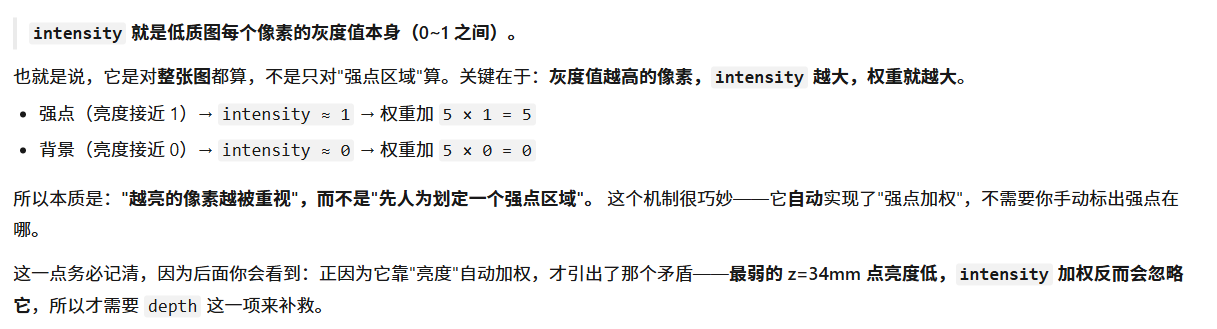
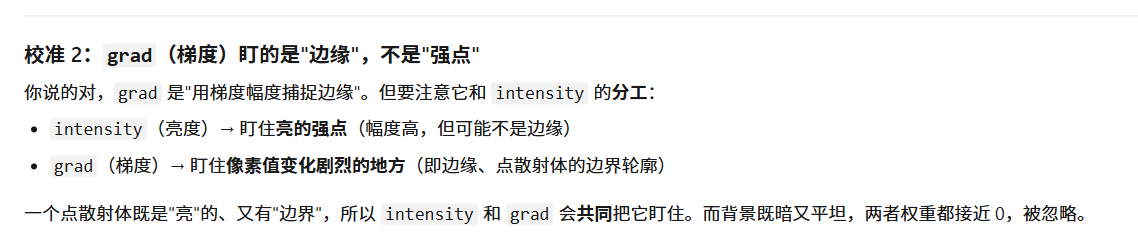
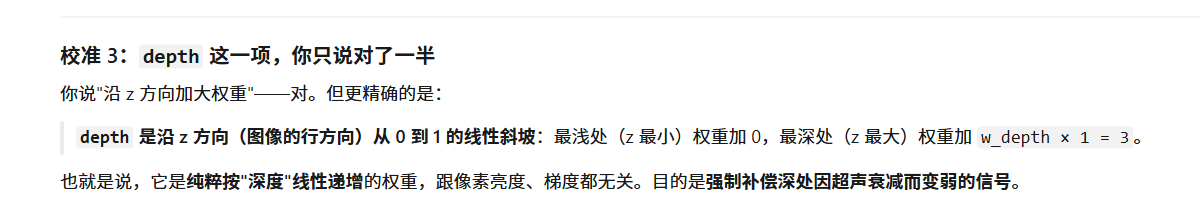
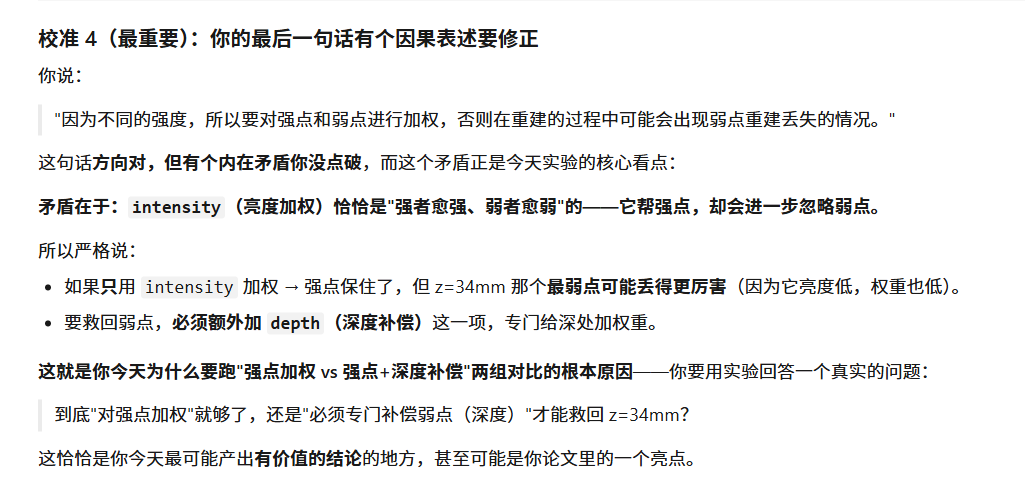

-   残差网络结构部分代码


In [ ]:
# ================= UNet（复用 11/19 骨架，加残差开关）=================
class ResUNet(nn.Module):
    """
    残差 UNet：输出学「残差 Δ」，最终重建 = 输入 + Δ。
    residual=True 时走残差分支；False 时退化为普通 UNet（等价 baseline）。
    """

    def __init__(self, in_ch=1, out_ch=1, base=16, residual=True):
        super().__init__()
        self.residual = residual

        def blk(a, b):
            return nn.Sequential(nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(True),
                                 nn.Conv2d(b, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(True))

        self.e1 = blk(in_ch, base); self.p = nn.MaxPool2d(2)
        self.e2 = blk(base, base * 2)
        self.e3 = blk(base * 2, base * 4)
        self.b = blk(base * 4, base * 8)
        self.u3 = nn.Sequential(nn.Conv2d(base * 8, base * 4 * 4, 1), nn.PixelShuffle(2)); self.d3 = blk(base * 8, base * 4)
        self.u2 = nn.Sequential(nn.Conv2d(base * 4, base * 2 * 4, 1), nn.PixelShuffle(2)); self.d2 = blk(base * 4, base * 2)
        self.u1 = nn.Sequential(nn.Conv2d(base * 2, base * 4, 1), nn.PixelShuffle(2)); self.d1 = blk(base * 2, base)
        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.p(e1)); e3 = self.e3(self.p(e2)); b = self.b(self.p(e3))
        d3 = self.d3(torch.cat([self.u3(b), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        delta = self.out(d1)
        if self.residual:
            return x + delta          # 残差：重建 = 低质 + Δ
        return delta                  # 普通：直接输出重建

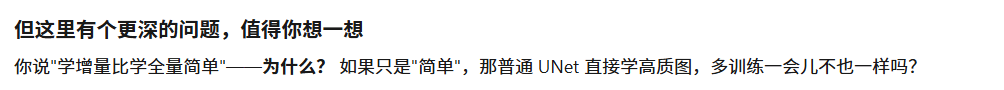
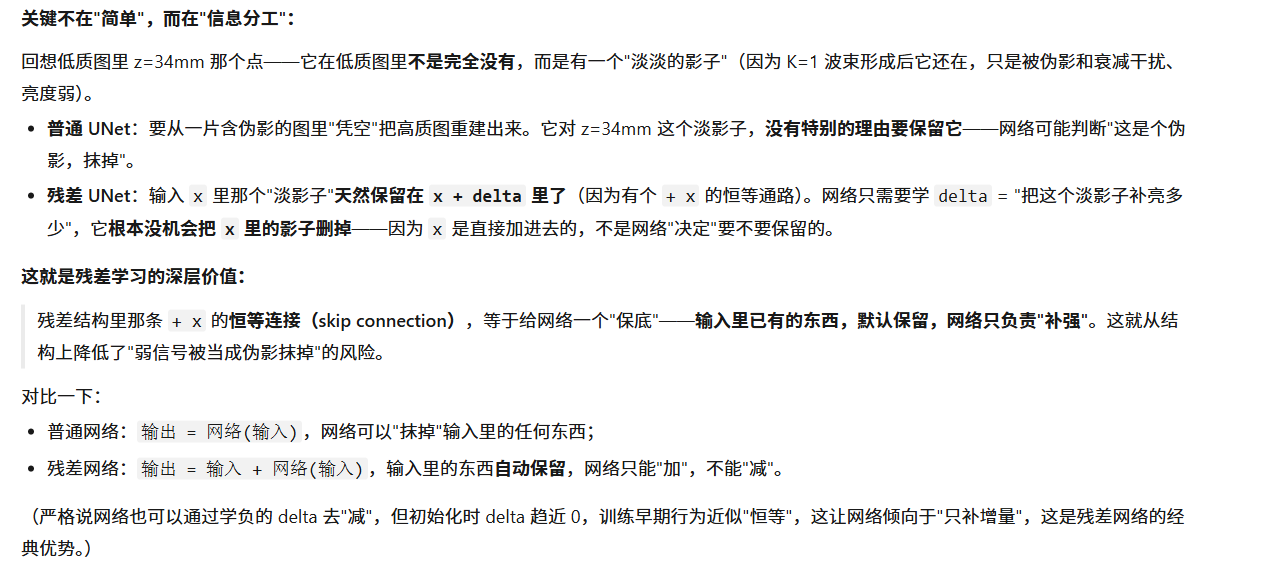
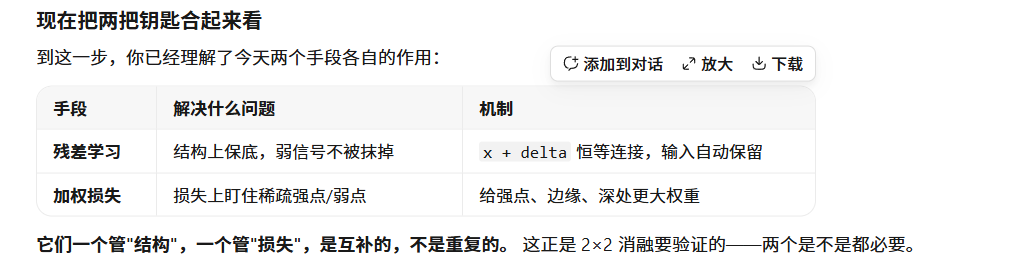


- 训练循环代码

In [ ]:

    # 4. 训练
    for ep in range(args.epochs):
        model.train()
        perm = torch.randperm(n_train)
        for i in range(0, n_train, bs):
            idx = perm[i:i + bs]
            xb, yb = Xt[idx], Yt[idx]
            opt.zero_grad()
            out = model(xb)
            if wloss is not None:
                loss = wloss(out, yb, xb)   # 加权：传入低质图算权重
            else:
                loss = l1(out, yb)
            loss.backward(); opt.step()

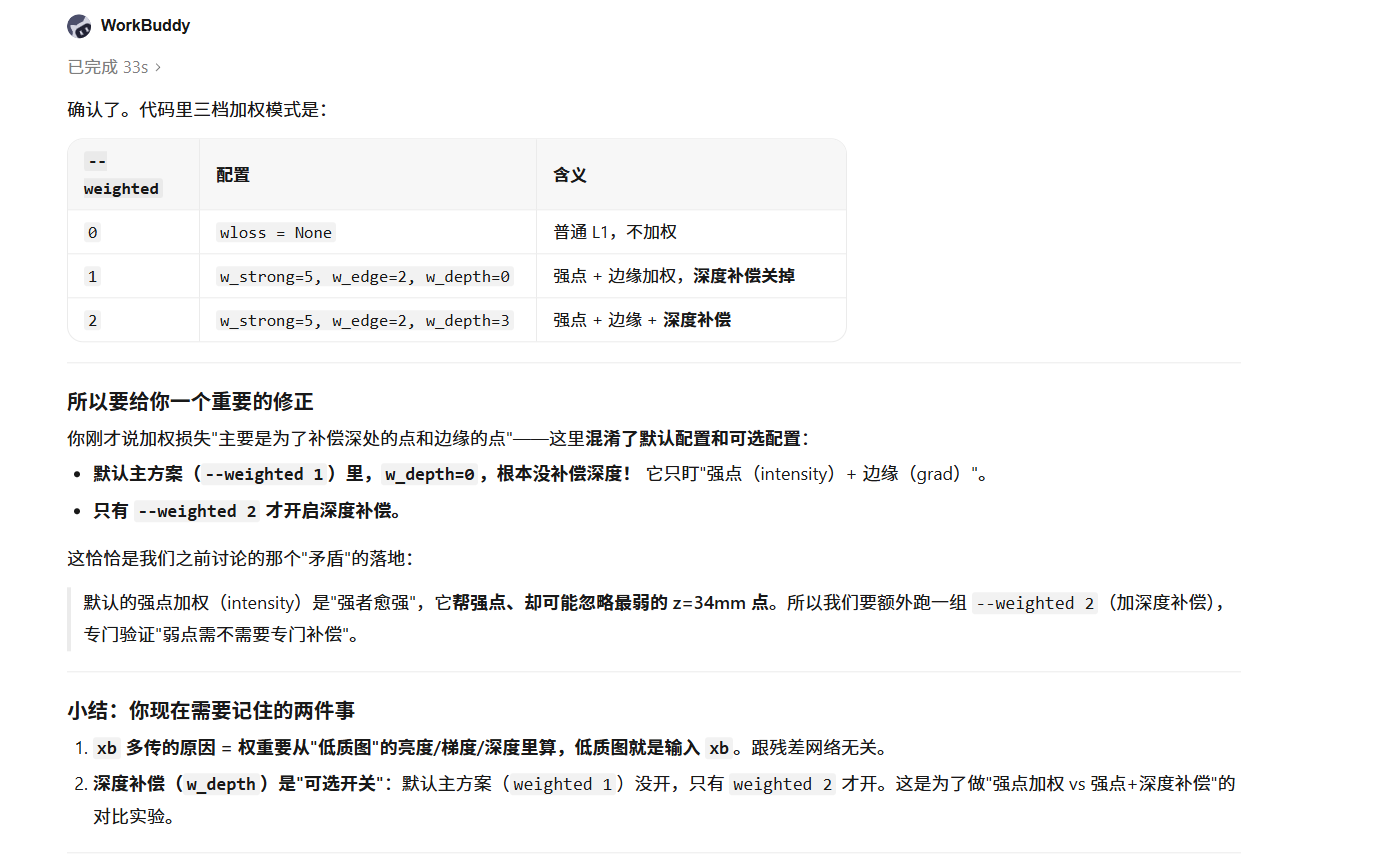

-   主流程部分代码

In [ ]:
# ================= 主流程 =================
if __name__ == "__main__":
    # 配置：可通过命令行切换残差/加权开关，做 2x2 消融
    import argparse
    ap = argparse.ArgumentParser()
    ap.add_argument("--residual", type=int, default=1, help="1=残差 0=普通")
    ap.add_argument("--weighted", type=int, default=1,
                    help="0=不加权(L1) 1=强点+边缘加权 2=强点+边缘+深度补偿")
    ap.add_argument("--epochs", type=int, default=100)
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    torch.manual_seed(args.seed); np.random.seed(args.seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    # 1. 训练集
    n_train = 200
    lows, ideals = [], []
    for _ in range(n_train):
        lo, hi = gen_pair()
        lows.append(lo); ideals.append(hi)
    lows = np.array(lows)[:, None, :, :].astype(np.float32)
    ideals = np.array(ideals)[:, None, :, :].astype(np.float32)

    # 2. 测试集（固定 3 个真点，同 11/19）
    test_sc = np.array([[0.0e-3, 12e-3, 1.0], [0.0e-3, 25e-3, 0.9], [0.0e-3, 34e-3, 0.8]])
    test_low = make_low_image(test_sc); test_low = test_low / (np.abs(test_low).max() + 1e-8)
    test_ideal = make_ideal_image(test_sc); test_ideal = test_ideal / (np.abs(test_ideal).max() + 1e-8)

    # 3. 模型 + 优化
    model = ResUNet(residual=bool(args.residual)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    l1 = nn.L1Loss()
    # 加权模式：1=强点+边缘，2=强点+边缘+深度补偿
    if args.weighted == 1:
        wloss = WeightedL1Loss(w_strong=5.0, w_edge=2.0, w_depth=0.0)
    elif args.weighted == 2:
        wloss = WeightedL1Loss(w_strong=5.0, w_edge=2.0, w_depth=3.0)
    else:
        wloss = None

    Xt = torch.from_numpy(lows).to(device)
    Yt = torch.from_numpy(ideals).to(device)
    bs = 16

    print(f"配置: residual={bool(args.residual)} weighted={args.weighted} | "
          f"epochs={args.epochs} | 设备={device}")

    # 4. 训练
    for ep in range(args.epochs):
        model.train()
        perm = torch.randperm(n_train)
        for i in range(0, n_train, bs):
            idx = perm[i:i + bs]
            xb, yb = Xt[idx], Yt[idx]
            opt.zero_grad()
            out = model(xb)
            if wloss is not None:
                loss = wloss(out, yb, xb)   # 加权：传入低质图算权重
            else:
                loss = l1(out, yb)
            loss.backward(); opt.step()

    # 5. 推理测试图
    model.eval()
    with torch.no_grad():
        tin = torch.from_numpy(test_low[None, None]).float().to(device)
        rec = model(tin).cpu().numpy()[0, 0]
    rec = np.clip(rec, 0, None); rec = rec / (np.abs(rec).max() + 1e-8)

    # 6. 四指标 + 点目标恢复率
    def pt_mask(x0, z0, hw=1.0e-3, hh=1.5e-3):
        return (np.abs(X - x0) <= hw) & (np.abs(Z - z0) <= hh)

    # 消声区当背景，真点1当目标
    in_mask = pt_mask(test_sc[0][0], test_sc[0][1])

    print("\n===== 四指标对比（baseline=低质图 vs 修复版重建）=====")
    print(f"PSNR:  低质={psnr(test_low, test_ideal):6.2f}dB | 重建={psnr(rec, test_ideal):6.2f}dB")
    print(f"SSIM:  低质={ssim(test_low, test_ideal):.4f}   | 重建={ssim(rec, test_ideal):.4f}")
    print(f"CNR:   低质={cnr(test_low, in_mask, anechoic_mask):8.2f} | 重建={cnr(rec, in_mask, anechoic_mask):8.2f}")
    print(f"gCNR:  低质={gcnr(test_low, in_mask, anechoic_mask):.4f}  | 重建={gcnr(rec, in_mask, anechoic_mask):.4f}")

    print("\n===== 点目标恢复率（核心：亮点有没有保住）=====")
    for i, (xk, zk, amp) in enumerate(test_sc):
        m = pt_mask(xk, zk)
        r = point_recovery(rec, test_ideal, m)
        print(f"  真点{i+1}(z={zk*1e3:.0f}mm): 恢复率={r:.3f}")

    # 7. 出图
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    fig, axes = plt.subplots(1, 3, figsize=(15, 8))
    for ax, im, t in zip(axes, [test_low, rec, test_ideal], ["低质图(K=1)", "残差+加权重建", "理想高质图"]):
        disp = 20 * np.log10(np.abs(im) / np.abs(im).max() + 1e-6)
        ax.imshow(disp, extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
                  cmap="gray", aspect="auto", vmin=-40, vmax=0)
        ax.set_title(t); ax.set_xlabel("x (mm)"); ax.set_ylabel("z (mm)")
    plt.tight_layout()
    out = f"residual{args.residual}_weighted{args.weighted}.png"
    plt.savefig(out, dpi=150)
    print(f"\n已保存对比图 {out}")

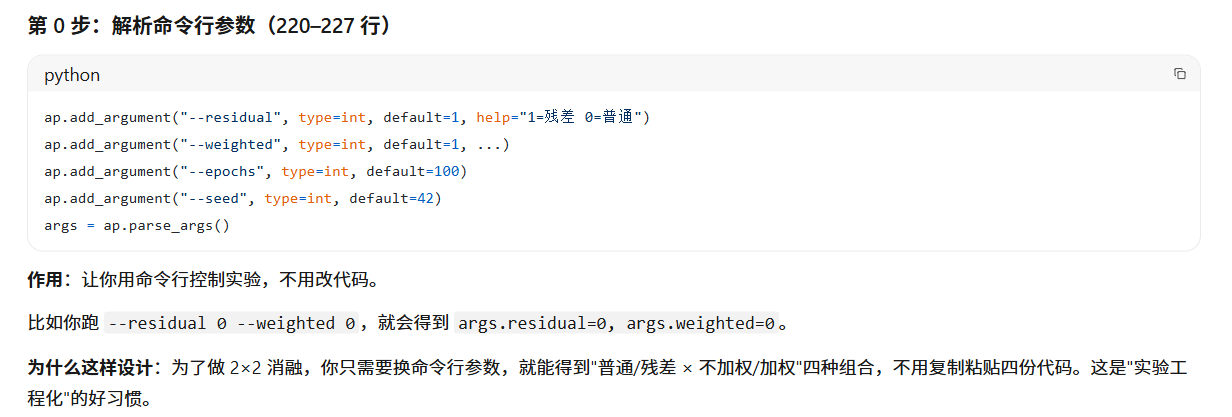
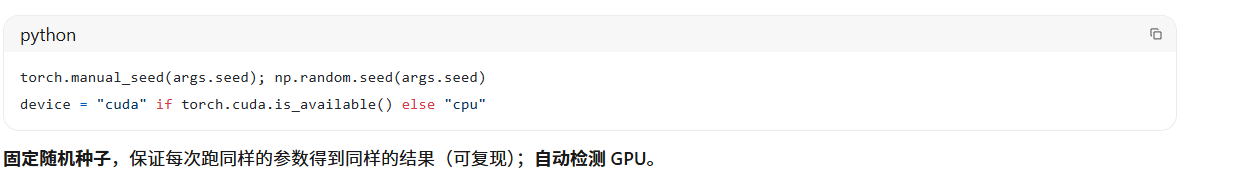
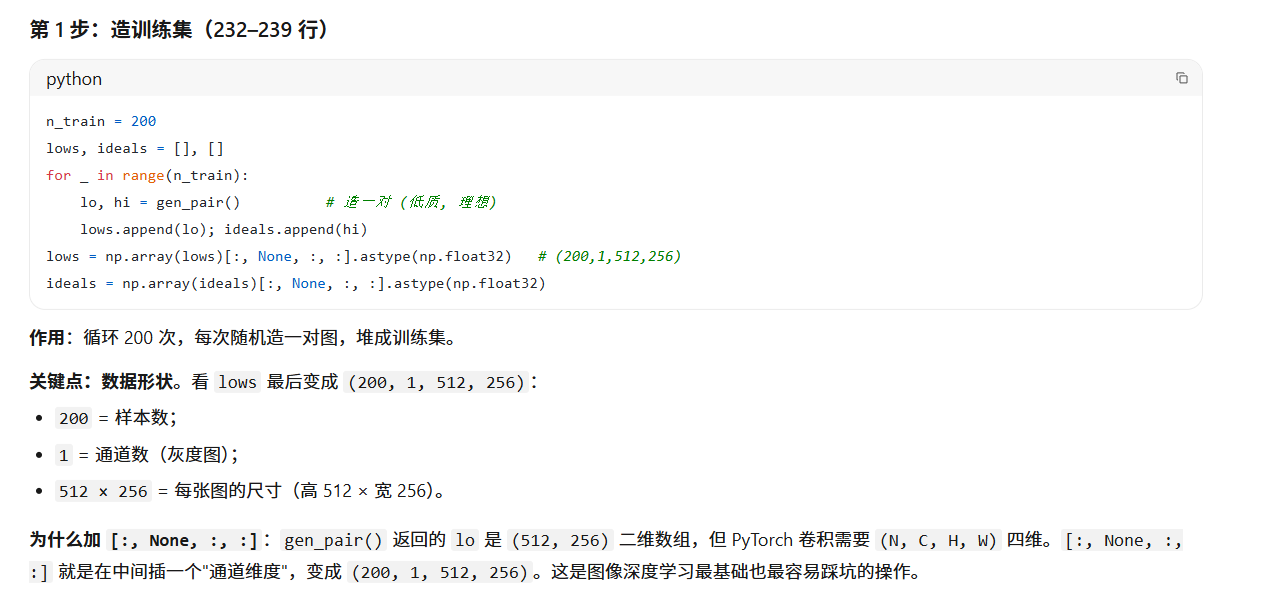
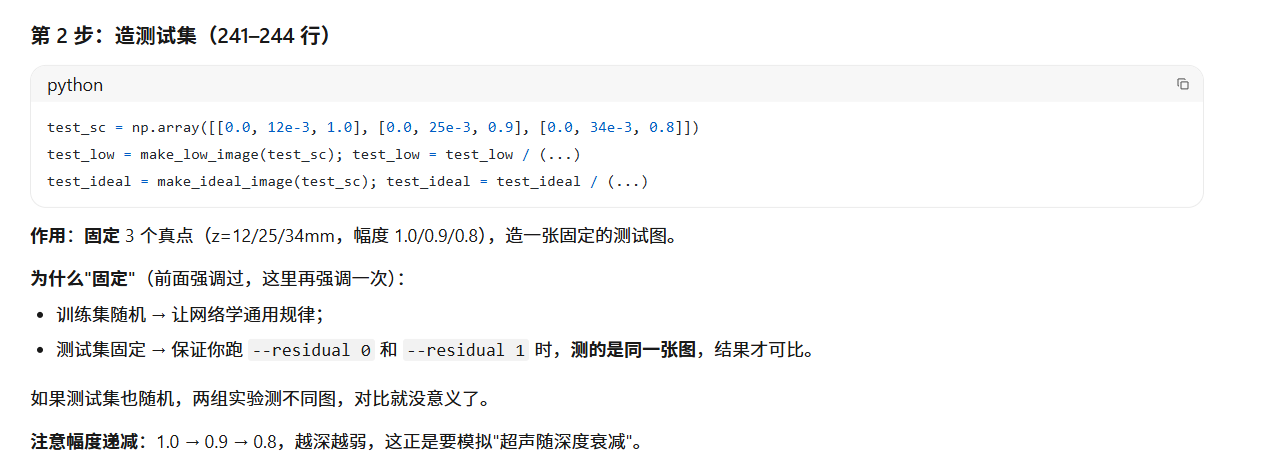
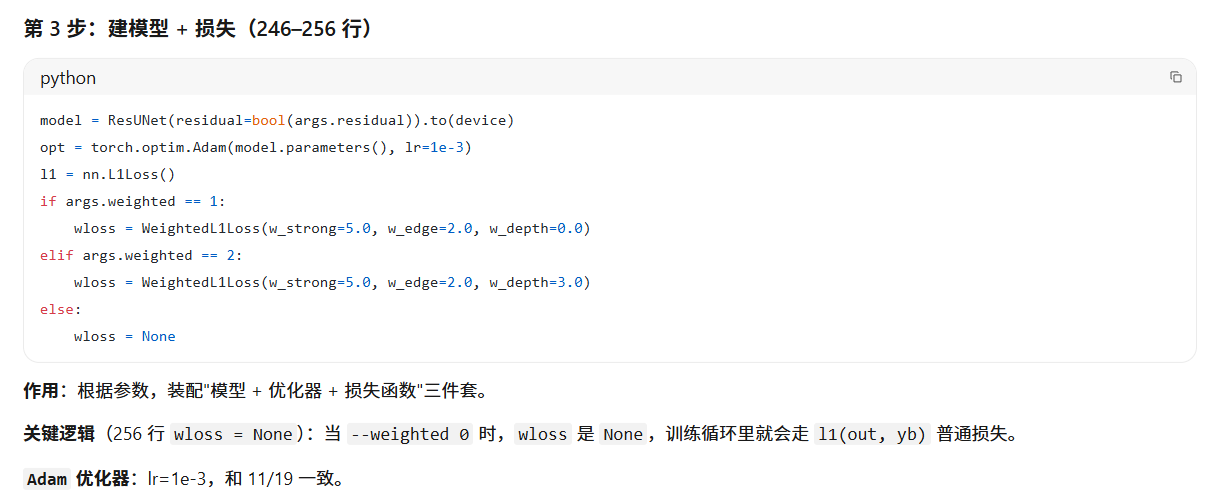
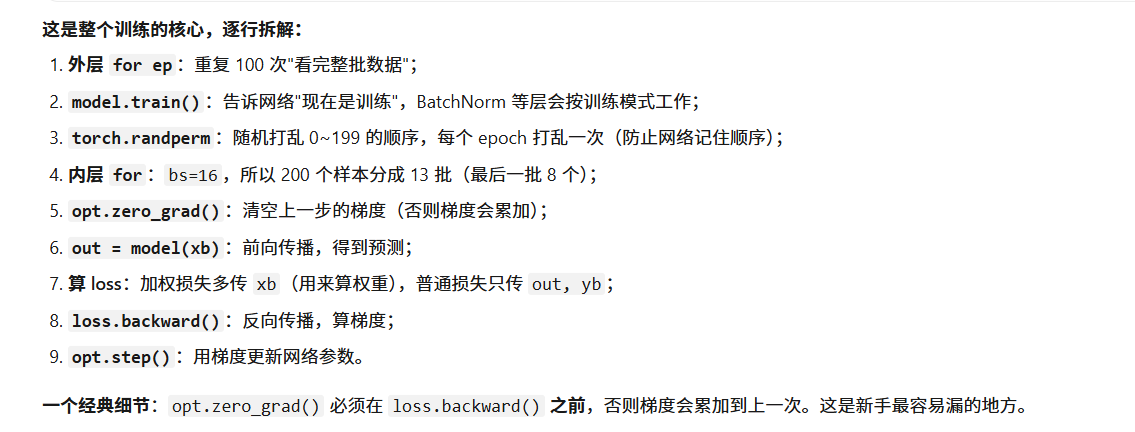
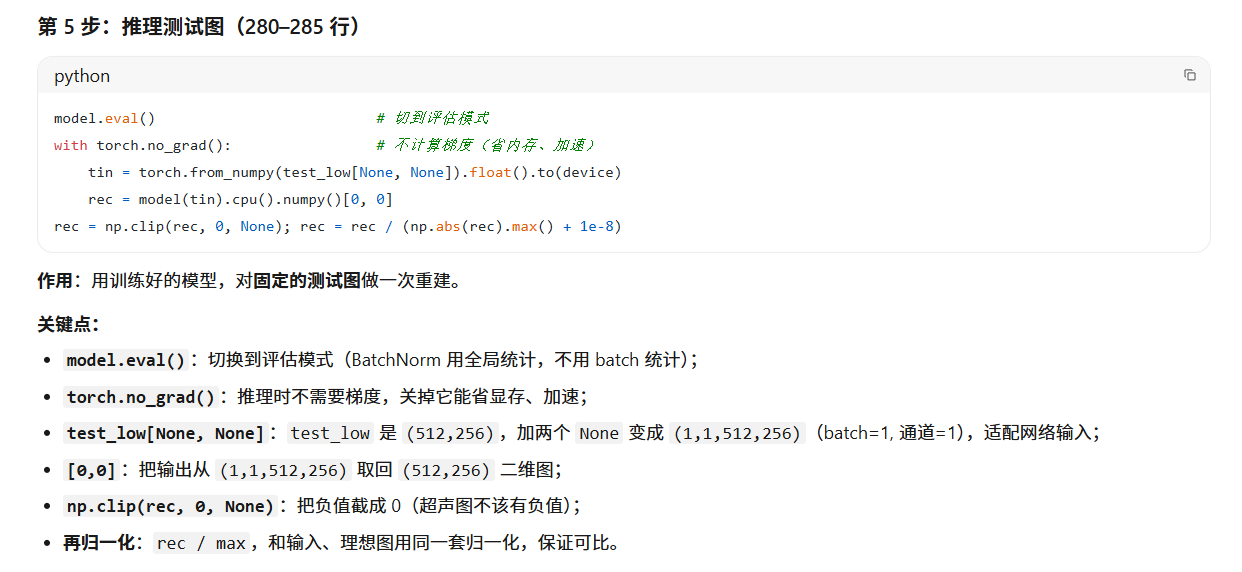
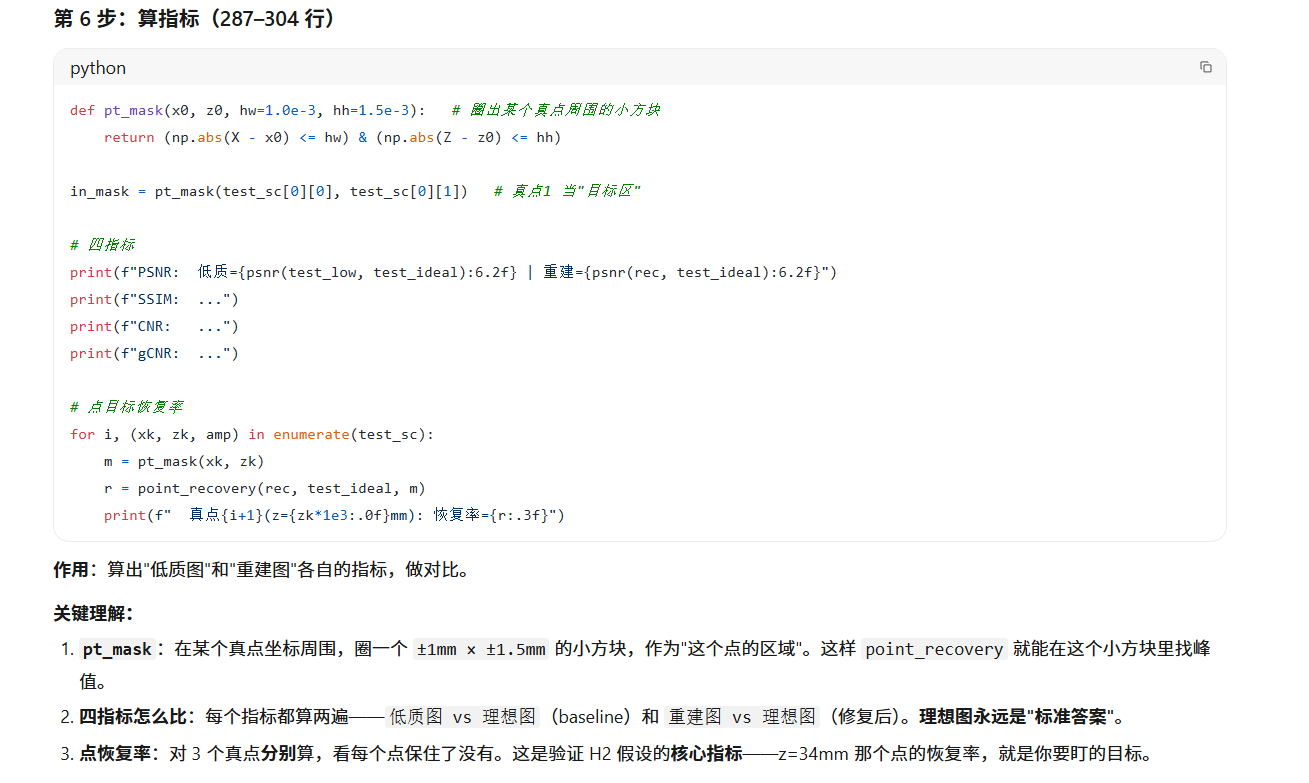
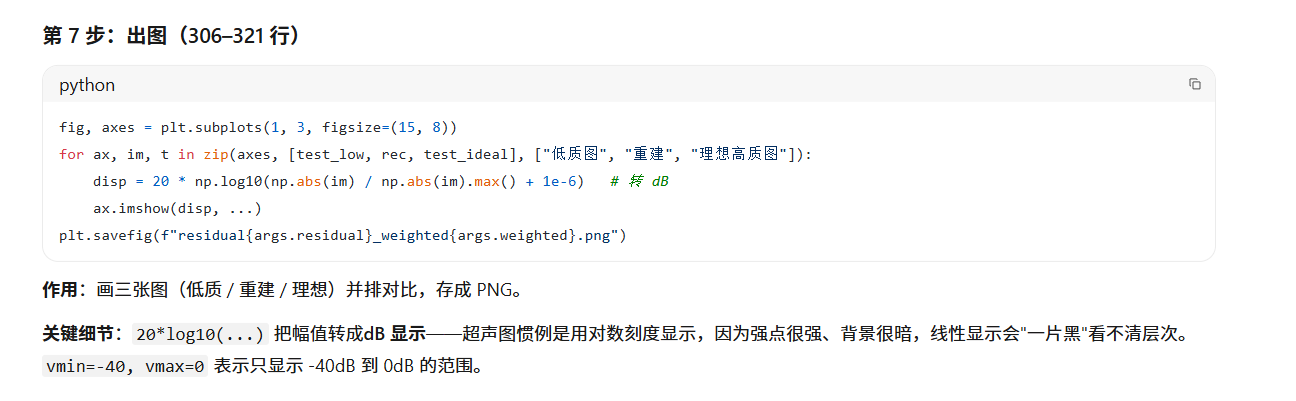
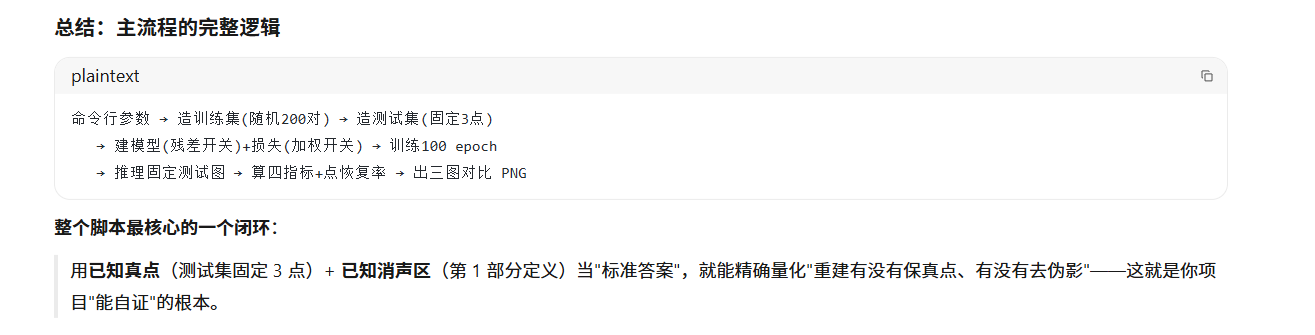

-   4.论文精读
    -   标题：Deep Coherence Learning: An Unsupervised Deep Beamformer for High Quality Single Plane Wave Imaging in Medical Ultrasound
        -   深度相关学习：用于医学超声中高质量单平面成像的无监督深度波束成形器
    -   核心任务：判断它有没有验证“去的是伪影而不是组织”
    -   Abstract：
        -   Plane wave imaging (PWI) in medical ultrasound is becoming an important reconstruction method with high frame rates and new clinical applications.
            -   医学超声中的平面波成像（PWI）正成为一种重要的重建方法，具有高帧率和新的临床应用。
        -   Recently, single PWI based on deep learning (DL) has been studied to overcome lowered frame rates of traditional PWI with multiple PW transmissions.
            -   最近，基于深度学习（DL）的单平面波成像被研究用于克服传统PWI在多路PWI传输中帧率降低的问题。
        -   However, due to the lack of appropriate ground truth images, DL-based PWI still remains challenging for performance improvements.
            -   然而，由于缺乏合适的地面真实图像，基于深度学习的PWI在性能提升方面仍然面临挑战。
        -   To address this issue, in this paper, we propose a new unsupervised learning approach, i.e., deep coherence learning (DCL)-based DL beamformer (DL-DCL), for high-quality single PWI.
            -   为解决这一问题，本文提出了一种新的无监督学习方法，即基于深度相干学习（DCL）的深度学习波束成形器（DL-DCL），用于实现高质量的单次脉冲波前成像。
        -   In DL-DCL, the DL network is trained to predict highly correlated signals with a unique loss function from a set of PW data, and the trained DL model encourages high-quality PWI from low-quality single PW data.
            -   在DL-DCL中，深度学习网络通过一组脉冲波（PW）数据，利用独特的损失函数来预测高度相关的信号，训练后的深度学习模型能够从低质量的单个脉冲波数据中生成高质量的脉冲波成像（PWI）。
        -   In addition, the DL-DCL framework based on complex baseband signals enables a universal beamformer.
            -   此外，基于复数基带信号的DL-DCL框架可实现通用波束成形。
        -   To assess the performance of DL-DCL, simulation, phantom and in vivo studies were conducted with public datasets, and it was compared with traditional beamformers (i.e., DAS with 75-PWs and DMAS with 1-PW) and other DL-based methods (i.e., supervised learning approach with 1 PW and generative adversarial network (GAN) with 1-PW).
            -   为了评估DL-DCL的性能，我们使用公开数据集进行了仿真、假体和体内研究，并将其与传统束形变器（即采用75个脉冲宽度的DAS和1个脉冲宽度的DMAS）以及其他基于深度学习的方法（如采用1个脉冲宽度的监督学习方法和1个脉冲宽度的生成对抗网络（GAN））进行了比较。
        -   From the experiments, the proposed DL-DCL showed comparable results with DMAS with 1-PW and DAS with 75-PWs in spatial resolution, and it outperformed all comparison methods in contrast resolution.
            -   实验表明，所提出的DL-DCL在空间分辨率方面与DMAS（1-PW）和DAS（75-PW）相当，并且在对比分辨率上优于所有比较方法。
        -   These results demonstrated that the proposed unsupervised learning approach can address the inherent limitations of traditional PWIs based on DL, and it also showed great potential in clinical settings with minimal artifacts.
            -   这些结果表明，所提出的无监督学习方法能够克服基于深度学习的传统PWIs固有的局限性，并且在临床应用中展现出极高的潜力，同时产生的伪影极少。
        -   摘要总结：
            -   它做的是无监督深度波束成形器，解决单平面波帧率差但质量差的问题
            -   用深度相干性损失训练网络，不需要ground truth，从低质量1-PW重建高质量图
            -   声称的结果：空间分辨率接近 DMAS(1-PW) 和 DAS(75-PW)，对比度分辨率超过所有方法
    -  Introduction：
       -  背景：PWI 帧率高，但单角度（1-PW）会有栅瓣/旁瓣伪影，质量差；传统做法是多角度（75-PW）叠加，但帧率下降。
       -  痛点：DL 方法需要 ground truth，但超声没有现成的"完美图"当 GT——这是它做无监督的动机。监督下需要大量高质量的真实数据，但是超声的数据并不足。
       -  它的切入点：相干性（coherence）​——高质量波束形成的信号之间"相关性高"，用这个当监督信号，绕开 GT 依赖。
       -  对你的启发：你的项目目前是"自仿真已知真点"当 GT（有监督），DCL 的"相干性损失"提供了一条无监督/弱监督的路，是块5之后可以想的扩展。
       -  监督学习需要大量"低质→高质"配对数据，而高质量超声图（ground truth）本身就稀缺、且被医院各自持有、难以共享 → 数据瓶颈是医学 AI 难落地的关键原因之一 → 无监督方法绕开"需要 GT"这个依赖。
       -  无监督不是"不要数据"，而是"不要 GT 标签"​。它仍然要吃大量低质量原始超声数据，但绕开了最稀缺、最难共享的那部分——高质量标注图。
       -  但无监督通常"质量天花板更低"​ ⚠️：因为监督学习的 GT 是"明确的正确答案"，网络学得准；而无监督的信号（相干性）只是"间接的、弱的正确答案"，它可能学到一个"看着像、但不是真"的解。DCL 论文自己也承认——它对比监督学习（DL-SP）时，质量并没有全面碾压，只是"在无 GT 的约束下"做到了可接受的水平。
       -  监督 = 有标准答案、质量上限高、但卡在"答案难搞"；无监督 = 不要标准答案、数据门槛低、但质量有妥协。DCL 选无监督，是因为"超声高质量 GT 太难拿"，而不是因为"无监督质量更好"。
    -  Methods——重点evaluation和loss
       -  3.1.2. Coherence Loss
          -  For this reason, a coherence loss function was developed to quantify the correlation between predicted and target signals for DCL. The coherence loss (𝐿𝐶𝑜ℎ𝑒𝑟𝑒𝑛𝑐𝑒) measures the correlation between the prediction (i.e., 𝑓(𝑃𝑖)) and target data (𝑃𝑡) for every pair of the input PW dataset:
             -  因此，开发了一种相干度损失函数，用于量化DCL中预测信号与目标信号之间的相关性。相干度损失（𝐿Coherence）衡量了输入PW数据集每一对中预测值（即 𝑓(𝑃𝑖)）与目标数据（𝑃𝑡）之间的相关性：
          -  where 𝑃𝑖 and 𝑃𝑡 denote the input and target I/Q data, respectively, and 𝑓 represents the deep learning prediction. In addition, ∗ is the complex conjugate of I/Q signals, and 𝑘 is the total number of PW images of CPWC. A negative sign of 𝐿𝐶𝑜ℎ𝑒𝑟𝑒𝑛𝑐𝑒 contributes to maximizing highly correlated signals as well as minimizing the overall loss.
             -  其中，Pi和Pt分别表示输入和目标的 I/Q 数据，f 表示深度学习预测结果。此外，*代表 I/Q 信号的复共轭，k是 CPWC 的 PW 图像总数。负号项 L_{coherence}有助于最大化高度相关信号，并最小化整体损失。
          -  网络输入单角度 PW 数据，用"相干性损失"训练，让输出信号在不同角度对之间高度相关。
          -  基于复基带（I/Q）信号，所以能做"通用波束形成器"（不依赖特定换能器）。
       -  3.3. Experimental Setup and Evaluation Metrics
          -  FWHM（轴向 + 横向）——测点扩散函数宽度 = 空间分辨率；
          -  PRSLL / PRAL——测旁瓣幅度相对主瓣 = 伪影抑制程度；
          -  CNR（公式 4）——消声区 vs 背景的对比度；
          -  gCNR（公式 5）——两区域分布的可分度。
          -  这 4 类指标里，没有任何一个测"真实点散射体/组织结构是否被保留"​。
    -  Experiments
       -  数据集：CUBDL + PICMUS（仿真 + phantom + in vivo，共 3715 帧）。
       -  对比方法：DAS(1-PW)、DAS(75-PW)、DMAS、监督学习 DL-SP、GAN。
       -  结果表/图：全部是 FWHM、PRSLL、CNR、gCNR 的数值对比 + B 模式图。
       -  键确认：它的仿真数据里虽然有已知的点散射体（phantom/simulation 能造已知点），但它没有利用这个"已知点"去做"点目标恢复率"的定量验证——只是把点当"测 FWHM 和 PRSLL 的靶子"，测的是"分辨率"和"旁瓣"，不是"点有没有被保住"。
       -  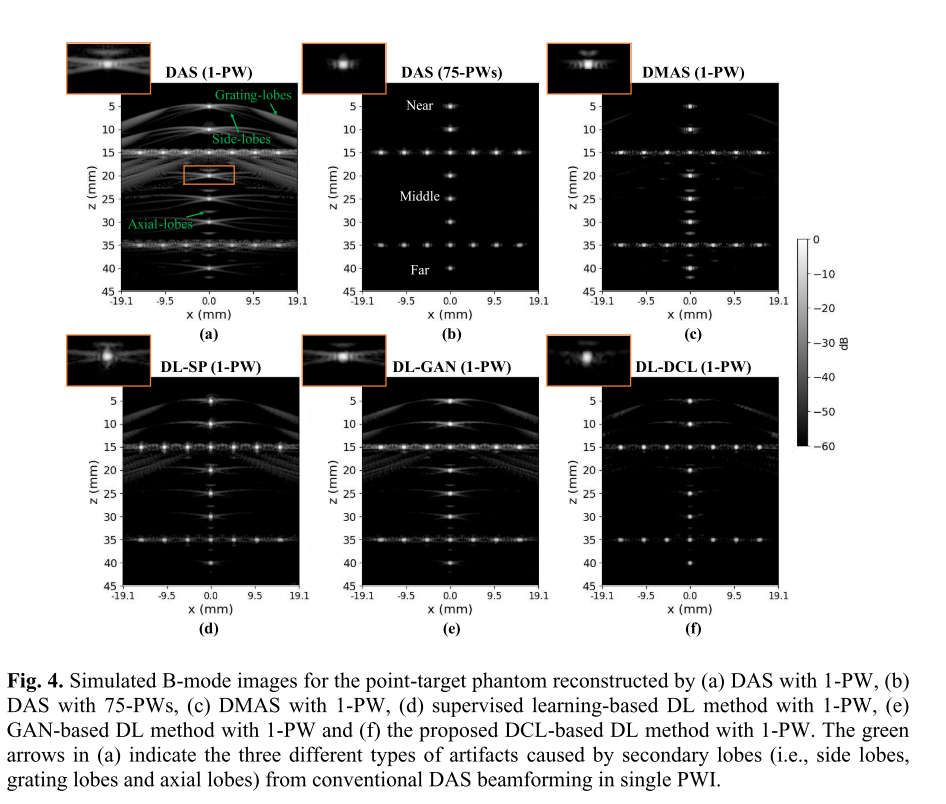
       -  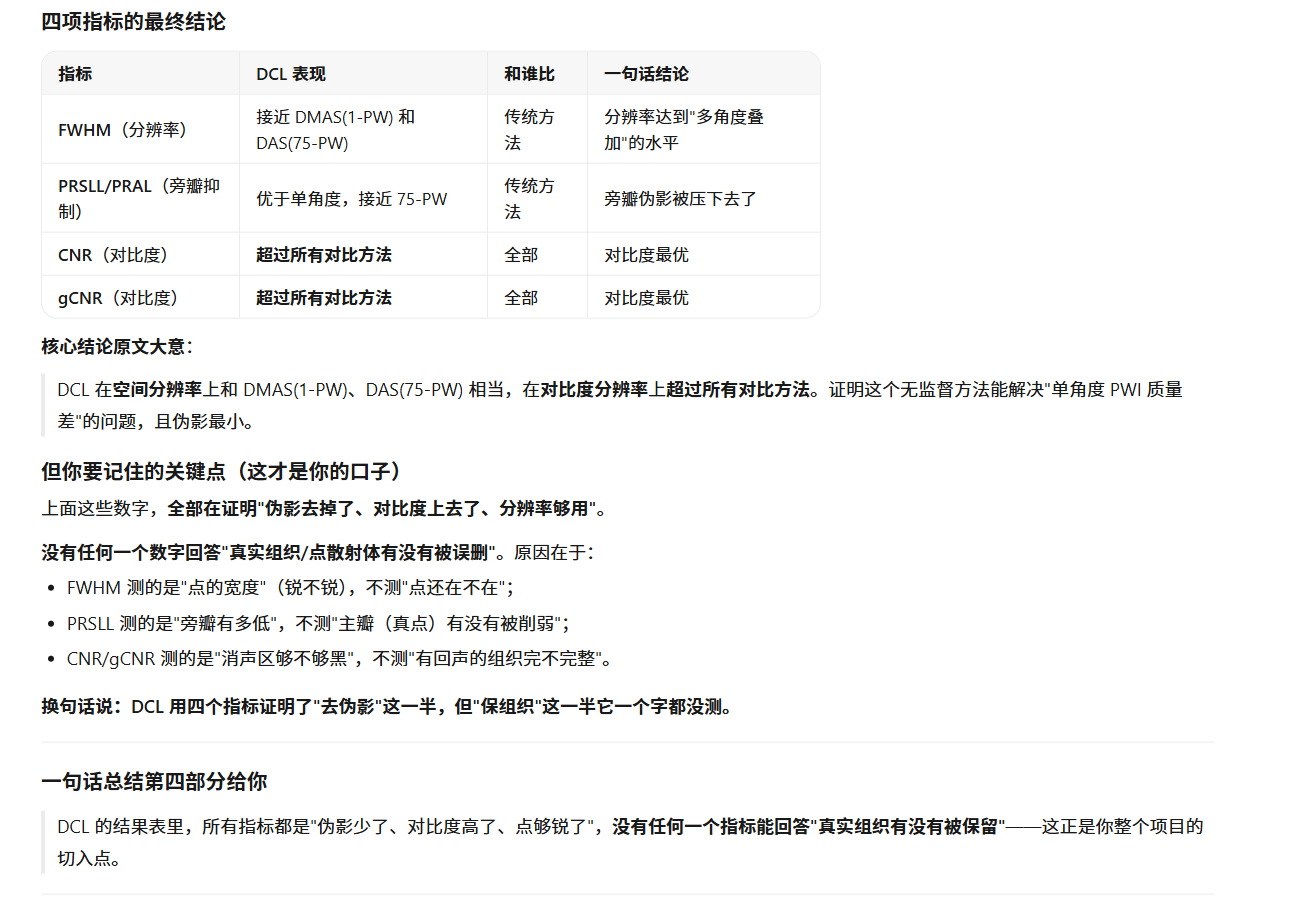
    -  Conclusion：
       -  In this article, a new unsupervised learning approach for high-quality images of a single PWI, named DCL, was proposed. The DCL leads the DL model to predict highly correlated signals from the CPWC dataset by a unique loss function, and the trained DL model encourages a high-image quality PWI from low-quality single PW data. To evaluate performance, simulation, phantom and in vivo studies were conducted, and the results were compared with those from several adaptive beamformers based on nonlinear operation (i.e., DMAS) and other DL networks (i.e., supervised learning method and GAN structure) as well as DAS with 75-PWs. In experiments, the proposed DCL showed comparable results with DMAS and DAS with 75-PWs in terms of spatial resolution, and it outperformed all comparison methods in terms of contrast resolution. The feasibility studies indicated that the proposed unsupervised learning approach can overcome the limitations of traditional DL methods based on supervised learning and showed great potential in clinical settings with minimal artifacts.
          -  本文提出了一种用于单个脉冲波成像（PWI）高质量图像的新型无监督学习方法，名为DCL。该方法通过独特的损失函数引导深度学习（DL）模型从CPWC数据集中预测高度相关的信号，并促使训练后的DL模型从低质量的单个PWI数据中生成高质量图像。为评估其性能，开展了仿真、假体及活体实验，并将结果与多种基于非线性操作的自适应波束成形器（如DMAS）、其他DL网络（如监督学习方法和GAN结构）以及采用75个PWI的DAS方法进行了对比。实验表明，所提出的DCL在空间分辨率方面与DMAS及75-PWI DAS表现相当，在对比度分辨率方面优于所有对比方法。可行性研究表明，该无监督学习方法能够克服传统基于监督学习的DL方法的局限性，在临床应用中具有极强潜力，且产生的伪影极少。
       -  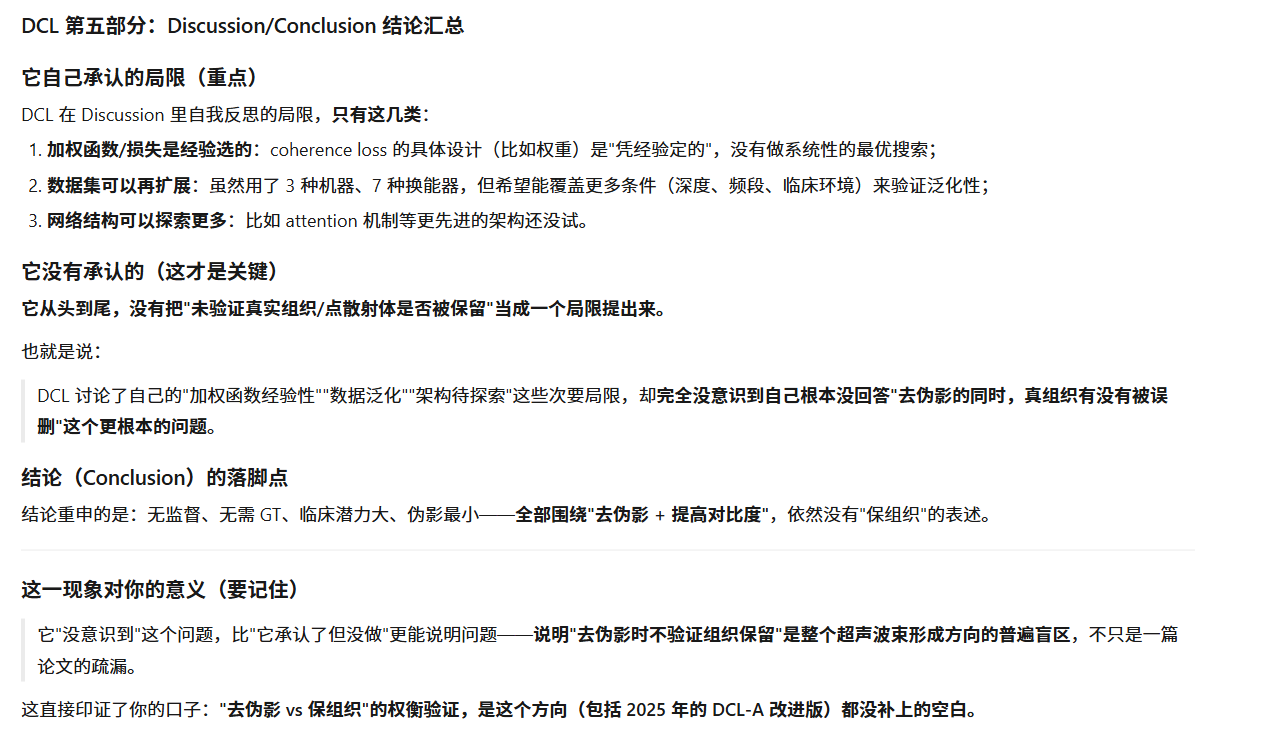

-   5.前沿阅读
    -   标题：Physics-Grounded Objective-Conditioned Deep Beamforming for Adaptive Resolution-Contrast Control in Plane-Wave Ultrasound Imaging
        -   基于物理的客观条件深度波束成形技术在平面波超声成像中实现自适应分辨率对比控制
        -   用你的 gap 读它（只问一个问题）
            -   它验证"去伪影/调对比度时，真组织有没有被保留"了吗？
                -   答案：没有，而且它做得比 DCL 更进一步地"只报对比度和分辨率"。​ 具体证据：  
                -   它的全部指标是：gCNR（+16.8%）、轴向分辨率（+22%）、横向 FWHM（-5.9%）、病灶对比度（±4.9%）。​还是那套 CNR/gCNR/FWHM 的组合，没有一个是"点目标恢复率 / 组织保留"。
        -   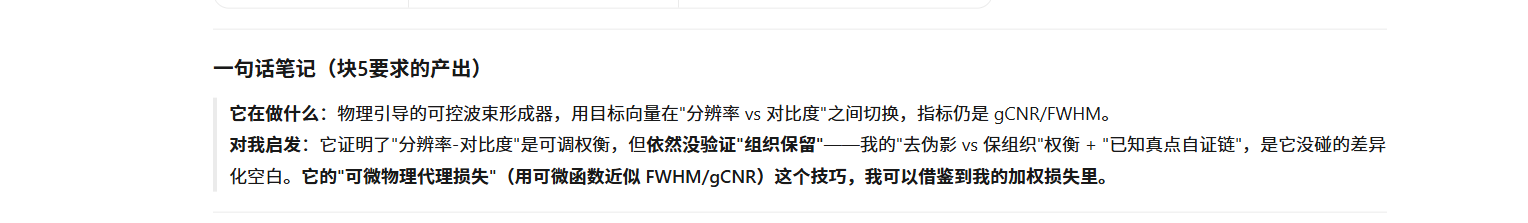